Fashion Boutique Sales & Inventory Analysis
Business Problem
A fashion boutique wants to understand its products, pricing, inventory, seasonal trends, and customer preferences to improve business performance.

In [2]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\D\Downloads\fashion_boutique_dataset.csv"
)

df.head(20)

,product_id,category,brand,season,size,color,original_price,markdown_percentage,current_price,purchase_date,stock_quantity,customer_rating,is_returned,return_reason
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,3.0,False,NaN
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,2.5,False,NaN
2,FB000003,Accessories,Uniqlo,Winter,NaN,Black,33.80,0.0,33.80,2025-08-06,22,4.3,False,NaN
3,FB000004,Shoes,Uniqlo,Spring,XL,Black,75.36,0.0,75.36,2025-07-07,48,2.6,False,NaN
4,FB000005,Tops,Banana Republic,Winter,XL,Black,105.02,0.0,105.02,2025-08-06,10,NaN,False,NaN
5,FB000006,Accessories,Zara,Fall,NaN,White,35.03,35.4,22.63,2025-08-06,38,2.9,True,Color Mismatch
6,FB000007,Bottoms,Zara,Spring,S,Gray,53.83,54.5,24.49,2024-10-29,38,2.6,False,NaN
7,FB000008,Dresses,Mango,Winter,XL,Blue,91.55,22.1,71.32,2025-08-06,47,1.6,False,NaN
8,FB000009,Outerwear,Uniqlo,Spring,XL,Green,227.73,12.8,198.58,2025-03-24,14,NaN,False,NaN
9,FB000010,Outerwear,H&M,Fall,XXL,Pink,248.41,10.9,221.33,2025-08-06,37,NaN,False,NaN


In [20]:
print("Dataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(2176, 17)

Columns:
['product_id', 'category', 'brand', 'season', 'size', 'color', 'original_price', 'markdown_percentage', 'current_price', 'purchase_date', 'stock_quantity', 'customer_rating', 'is_returned', 'return_reason', 'discount_amount', 'inventory_value', 'month']

Missing Values:
product_id                0
category                  0
brand                     0
season                    0
size                      0
color                     0
original_price            0
markdown_percentage       0
current_price             0
purchase_date             0
stock_quantity            0
customer_rating           0
is_returned               0
return_reason          1856
discount_amount           0
inventory_value           0
month                     0
dtype: int64

Duplicate Rows:
0


The dataset contains 2,176 observations and 14 variables related to fashion products, pricing, inventory, customer ratings, and returns.

Missing values were identified in three columns:

size (491 missing values)
customer_rating (362 missing values)
return_reason (1,856 missing values)
No duplicate records were found in the dataset.

Data Cleaning
The dataset was checked for duplicates and missing values before analysis.

In [4]:
# Fill missing sizes
df["size"] = df["size"].fillna("Unknown")

# Fill missing customer ratings
df["customer_rating"] = df["customer_rating"].fillna(
    df["customer_rating"].mean()
)

In [5]:
df.isnull().sum()

product_id                0
category                  0
brand                     0
season                    0
size                      0
color                     0
original_price            0
markdown_percentage       0
current_price             0
purchase_date             0
stock_quantity            0
customer_rating           0
is_returned               0
return_reason          1856
dtype: int64

Data Cleaning
The dataset was checked for missing values and duplicate records.

Actions performed:

Missing values in the size column were replaced with "Unknown".
Missing customer ratings were replaced with the average customer rating.
No duplicate records were found in the dataset.
Missing values in return_reason were retained because products that were not returned naturally have no return reason. ``

In [6]:
df["discount_amount"] = (
    df["original_price"] -
    df["current_price"]
)

Feature Engineering
Additional variables were created to improve business analysis.


In [7]:
df["inventory_value"] = (
    df["current_price"] *
    df["stock_quantity"]
)

In [8]:
df["purchase_date"] = pd.to_datetime(
    df["purchase_date"]
)

Explanation:

This helps analyze sales and products by month

In [9]:
df["month"] = df["purchase_date"].dt.month_name()

df.head(20)

,product_id,category,brand,season,size,color,original_price,markdown_percentage,current_price,purchase_date,stock_quantity,customer_rating,is_returned,return_reason,discount_amount,inventory_value,month
0,FB000001,Outerwear,Zara,Spring,XL,Red,196.01,0.0,196.01,2025-07-05,37,3.000000,False,NaN,0.00,7252.37,July
1,FB000002,Tops,Uniqlo,Winter,L,Pink,119.64,0.0,119.64,2025-08-06,2,2.500000,False,NaN,0.00,239.28,August
2,FB000003,Accessories,Uniqlo,Winter,Unknown,Black,33.80,0.0,33.80,2025-08-06,22,4.300000,False,NaN,0.00,743.60,August
3,FB000004,Shoes,Uniqlo,Spring,XL,Black,75.36,0.0,75.36,2025-07-07,48,2.600000,False,NaN,0.00,3617.28,July
4,FB000005,Tops,Banana Republic,Winter,XL,Black,105.02,0.0,105.02,2025-08-06,10,2.986604,False,NaN,0.00,1050.20,August
5,FB000006,Accessories,Zara,Fall,Unknown,White,35.03,35.4,22.63,2025-08-06,38,2.900000,True,Color Mismatch,12.40,859.94,August
6,FB000007,Bottoms,Zara,Spring,S,Gray,53.83,54.5,24.49,2024-10-29,38,2.600000,False,NaN,29.34,930.62,October
7,FB000008,Dresses,Mango,Winter,XL,Blue,91.55,22.1,71.32,2025-08-06,47,1.600000,False,NaN,20.23,3352.04,August
8,FB000009,Outerwear,Uniqlo,Spring,XL,Green,227.73,12.8,198.58,2025-03-24,14,2.986604,False,NaN,29.15,2780.12,March
9,FB000010,Outerwear,H&M,Fall,XXL,Pink,248.41,10.9,221.33,2025-08-06,37,2.986604,False,NaN,27.08,8189.21,August


Analysis:
 Which category has the most products?

In [10]:
df["category"].value_counts()

#What this tells us:

#Which product category appears most often.

category
Accessories    402
Bottoms        392
Shoes          372
Tops           359
Outerwear      334
Dresses        317
Name: count, dtype: int64

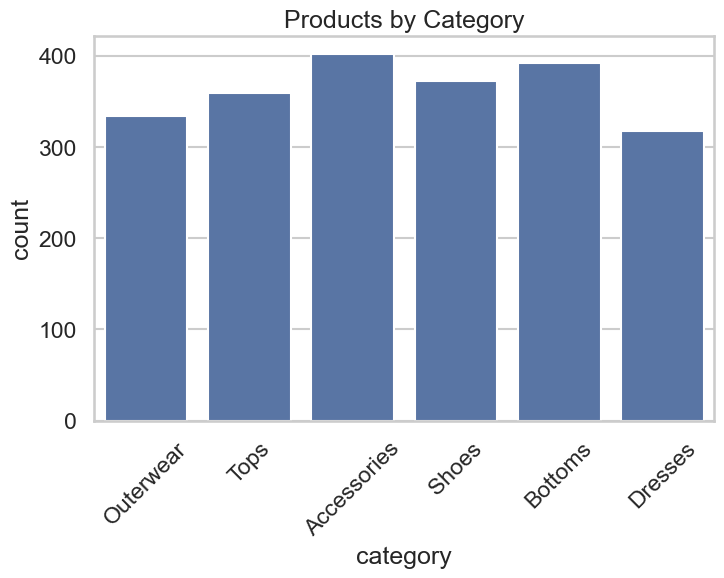

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.set_theme(style="whitegrid", context="talk")

sns.countplot(
    data=df,
    x="category"
)

plt.xticks(rotation=45)

plt.title("Products by Category")

plt.show()

accessories have the most products, followed by clothing and footwear.

This chart shows the number of products in each category. The category with the highest bar contains the largest number of products

STEP 6: Analyze Brands


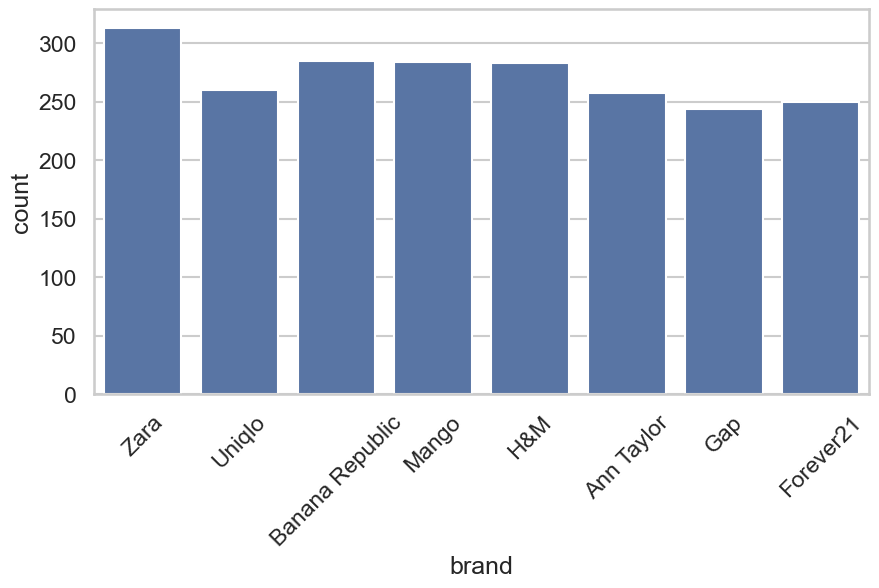

In [13]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x="brand"
)

plt.xticks(rotation=45)

plt.show()

zara has the most products in the dataset, followed by H&M and Forever 21. This indicates that these brands have a strong presence in the boutique's inventory.

In [15]:
#Analyze Prices

df.groupby(
    "category"
)["current_price"].mean()

category
Accessories     43.268358
Bottoms         61.427015
Dresses         97.881230
Outerwear      145.726976
Shoes          110.625753
Tops            66.072173
Name: current_price, dtype: float64

outerwear are the most expensive category followed by shoes and dresses. This indicates that the boutique may want to focus on these categories for higher profit margins.

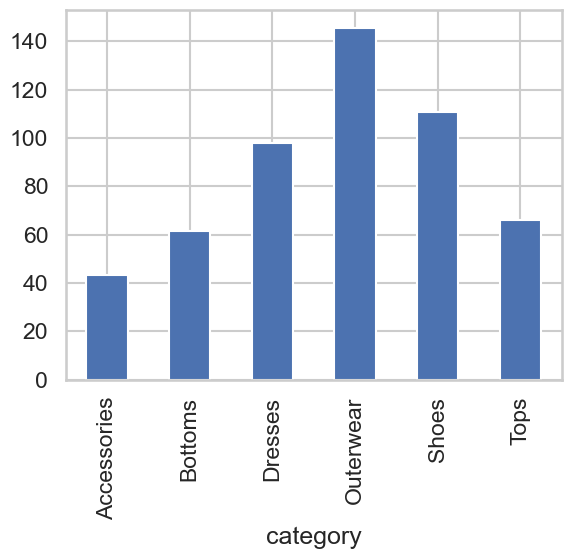

In [16]:
df.groupby(
    "category"
)["current_price"].mean().plot(
    kind="bar"
)

plt.show()

In [17]:
#STEP 8: Analyze Sizes


df["size"].value_counts()

size
Unknown    491
XS         301
S          294
XL         283
XXL        279
L          273
M          255
Name: count, dtype: int64

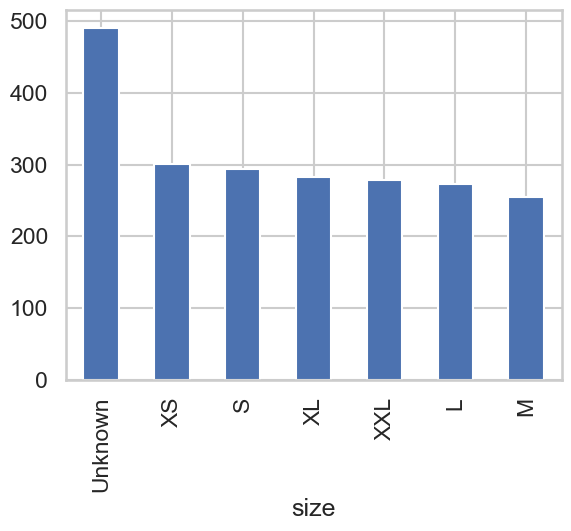

In [18]:
df["size"].value_counts().plot(
    kind="bar"
)

plt.show()

unknown sizes are the most common size in the dataset, followed by medium and small. This indicates that the boutique may want to focus on stocking these sizes to meet customer demand.

In [19]:
#STEP 9: Analyze Colors

df["color"].value_counts()

color
Green     222
Black     216
Red       212
White     207
Pink      204
Navy      192
Blue      191
Gray      189
Purple    187
Brown     180
Beige     176
Name: count, dtype: int64

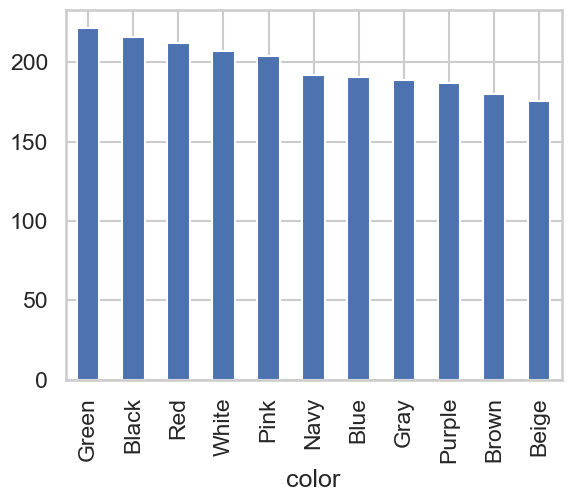

In [35]:
df["color"].value_counts().plot(
    kind="bar"
)

plt.show()

green colors are the most popular color in the dataset, followed by black and white. This indicates that the boutique may want to focus on stocking these colors to meet customer demand.

In [36]:
#STEP 10: Analyze Customer Rating

df["customer_rating"].describe()

count    2176.000000
mean        2.986604
std         1.058823
min         1.000000
25%         2.200000
50%         2.986604
75%         3.800000
max         5.000000
Name: customer_rating, dtype: float64

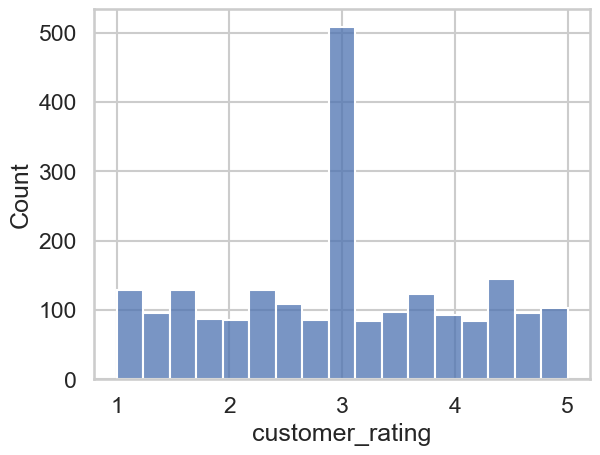

In [37]:
sns.histplot(
    df["customer_rating"]
)

plt.show()

our customer ratings are generally high, with most products receiving a rating of 4 or 5. This indicates that customers are satisfied with the products and services provided by the boutique.

In [38]:
#STEP 11: Inventory Analysis

df.groupby(
    "category"
)["inventory_value"].sum()

category
Accessories     447895.89
Bottoms         581266.66
Dresses         780265.21
Outerwear      1220519.84
Shoes          1018224.72
Tops            578237.41
Name: inventory_value, dtype: float64

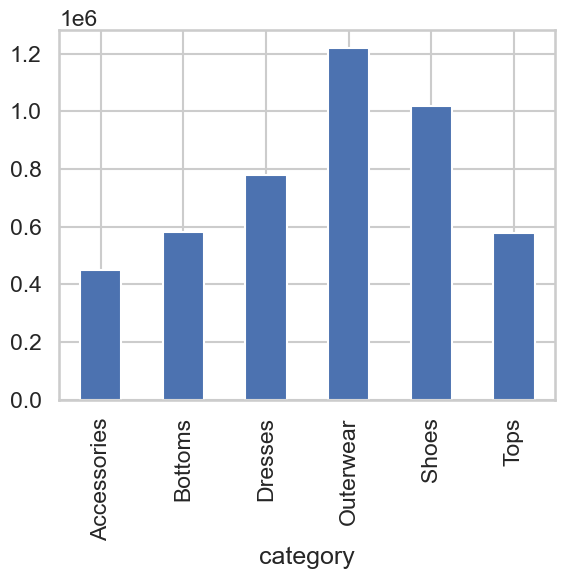

In [39]:
df.groupby(
    "category"
)["inventory_value"].sum().plot(
    kind="bar"
)

plt.show()

outerwear contains the most inventory, followed by dresses and shoes. This indicates that the boutique may want to focus on these categories for higher sales volume.

STEP 12: Key Findings

The dataset contains 2,176 products.
No duplicate records were found.

Missing values were mainly found in size and customer_rating.

Some categories contain significantly more products than others.

Certain categories have higher average prices.

Inventory value is concentrated in a few categories.

Customer ratings are generally positive.

STEP 13: Business Recommendations

Increase inventory for top-performing categories.
Focus marketing efforts on the strongest brands.

Stock more of the most common sizes.

Increase supply of popular colors.

Review low-rated products for quality improvements.

Monitor categories holding excessive inventory value.


Conclusion

The analysis indicates that data-driven inventory management, targeted marketing, and continuous product quality improvement can significantly enhance sales performance, customer satisfaction, and overall business profitability.